In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python is working!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python is working!
Pandas version: 3.1.0
NumPy version: 2.4.6


In [2]:
from pathlib import Path
import pandas as pd

# Locate the dataset
file_path = Path("../data/raw/synthetic_burnin_dataset.csv")

# Check whether the file exists
if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path.resolve()}"
    )

# Load the dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("-" * 40)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first 10 rows
display(df.head(10))

Dataset loaded successfully!
----------------------------------------
Number of rows: 1000
Number of columns: 8


,Component_ID,Lot_ID,Value_0h,Value_24h,Value_96h,Value_168h,Component_Type,Ground_Truth
0,C0001,L01,10.248,12.193,16.304,24.622,Gradual_Degradation,Anomaly
1,C0002,L01,10.140,12.544,17.168,25.711,Gradual_Degradation,Anomaly
2,C0003,L01,9.768,10.175,10.391,11.772,Normal,Normal
3,C0004,L01,10.408,10.603,11.331,11.766,Normal,Normal
4,C0005,L01,10.733,11.188,12.956,14.113,Normal,Normal
5,C0006,L01,10.061,10.458,11.278,12.161,Normal,Normal
6,C0007,L01,9.699,10.570,11.410,12.407,Normal,Normal
7,C0008,L01,9.885,10.463,11.526,11.742,Normal,Normal
8,C0009,L01,9.336,16.533,28.970,44.734,Latent_Defect,Anomaly
9,C0010,L01,9.495,9.679,10.541,11.963,Normal,Normal


In [3]:
print("Dataset column names:")
print(df.columns.tolist())

Dataset column names:
['Component_ID', 'Lot_ID', 'Value_0h', 'Value_24h', 'Value_96h', 'Value_168h', 'Component_Type', 'Ground_Truth']


In [4]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


,Missing Values
Component_ID,0
Lot_ID,0
Value_0h,0
Value_24h,0
Value_96h,0
Value_168h,0
Component_Type,0
Ground_Truth,0


Duplicate rows: 0


In [5]:
# Display column names and data types
print("DATASET INFORMATION")
df.info()

print("\nFIRST 10 ROWS")
display(df.head(10))

print("\nGROUND TRUTH LABELS")
print(df["Ground_Truth"].value_counts())

print("\nCOMPONENT TYPES")
print(df["Component_Type"].value_counts())

print("\nNUMERICAL SUMMARY")
display(df.describe())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Component_ID    1000 non-null   str    
 1   Lot_ID          1000 non-null   str    
 2   Value_0h        1000 non-null   float64
 3   Value_24h       1000 non-null   float64
 4   Value_96h       1000 non-null   float64
 5   Value_168h      1000 non-null   float64
 6   Component_Type  1000 non-null   str    
 7   Ground_Truth    1000 non-null   str    
dtypes: float64(4), str(4)
memory usage: 85.6 KB

FIRST 10 ROWS


,Component_ID,Lot_ID,Value_0h,Value_24h,Value_96h,Value_168h,Component_Type,Ground_Truth
0,C0001,L01,10.248,12.193,16.304,24.622,Gradual_Degradation,Anomaly
1,C0002,L01,10.140,12.544,17.168,25.711,Gradual_Degradation,Anomaly
2,C0003,L01,9.768,10.175,10.391,11.772,Normal,Normal
3,C0004,L01,10.408,10.603,11.331,11.766,Normal,Normal
4,C0005,L01,10.733,11.188,12.956,14.113,Normal,Normal
5,C0006,L01,10.061,10.458,11.278,12.161,Normal,Normal
6,C0007,L01,9.699,10.570,11.410,12.407,Normal,Normal
7,C0008,L01,9.885,10.463,11.526,11.742,Normal,Normal
8,C0009,L01,9.336,16.533,28.970,44.734,Latent_Defect,Anomaly
9,C0010,L01,9.495,9.679,10.541,11.963,Normal,Normal



GROUND TRUTH LABELS
Ground_Truth
Normal     717
Anomaly    283
Name: count, dtype: int64

COMPONENT TYPES
Component_Type
Normal                 717
Gradual_Degradation    142
Sudden_Degradation      85
Latent_Defect           56
Name: count, dtype: int64

NUMERICAL SUMMARY


,Value_0h,Value_24h,Value_96h,Value_168h
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,10.016404,11.089833,14.435697,17.519548
std,0.482166,1.603827,5.472376,8.831630
min,8.496000,9.026000,9.616000,10.331000
25%,9.678000,10.264500,11.304250,12.281250
50%,10.019000,10.696500,11.816000,12.854000
75%,10.362500,11.239250,16.253000,23.874000
max,11.686000,19.572000,33.933000,50.468000


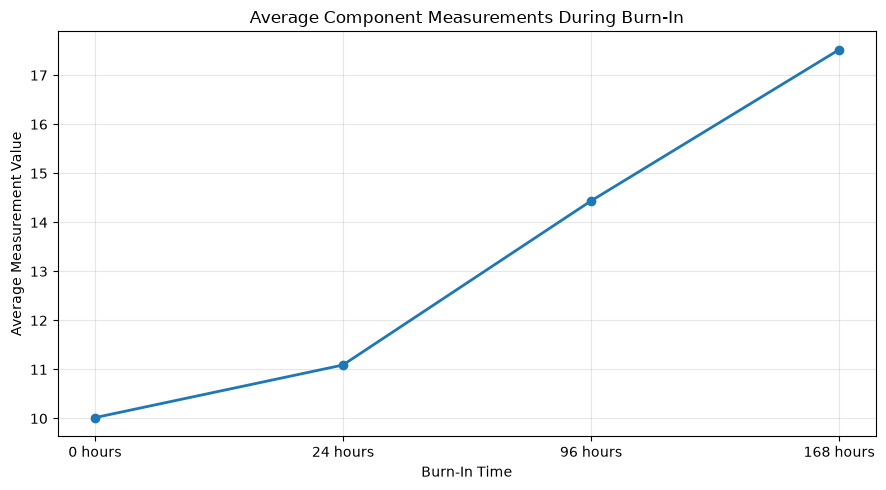

In [6]:
import matplotlib.pyplot as plt

# Plot the average measurement at each burn-in time
time_columns = ["Value_0h", "Value_24h", "Value_96h", "Value_168h"]

average_values = df[time_columns].mean()

plt.figure(figsize=(9, 5))
plt.plot(
    ["0 hours", "24 hours", "96 hours", "168 hours"],
    average_values.values,
    marker="o",
    linewidth=2
)

plt.title("Average Component Measurements During Burn-In")
plt.xlabel("Burn-In Time")
plt.ylabel("Average Measurement Value")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,Value_0h,Value_24h,Value_96h,Value_168h
Ground_Truth,,,,
Anomaly,10.025498,12.538728,21.859332,30.185279
Normal,10.012815,10.517954,11.505587,12.520382


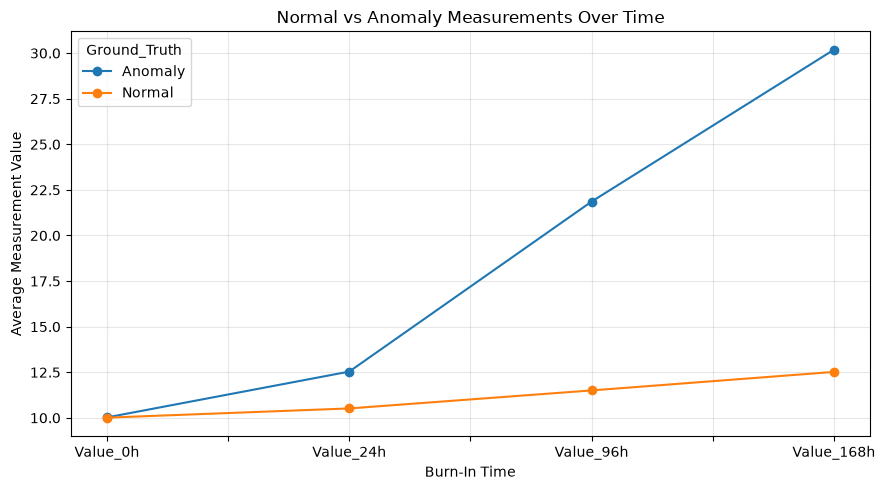

In [7]:
import matplotlib.pyplot as plt

time_columns = ["Value_0h", "Value_24h", "Value_96h", "Value_168h"]

group_means = df.groupby("Ground_Truth")[time_columns].mean()

display(group_means)

group_means.T.plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("Normal vs Anomaly Measurements Over Time")
plt.xlabel("Burn-In Time")
plt.ylabel("Average Measurement Value")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Select the measurement features
feature_columns = [
    "Value_0h",
    "Value_24h",
    "Value_96h",
    "Value_168h"
]

X = df[feature_columns].copy()

# Encode the target labels:
# Normal = 0, Anomaly = 1
y = df["Ground_Truth"].map({
    "Normal": 0,
    "Anomaly": 1
})

print("Features prepared successfully!")
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().rename(index={
    0: "Normal",
    1: "Anomaly"
}))

display(X.head())

Features prepared successfully!
Feature matrix shape: (1000, 4)
Target shape: (1000,)

Target distribution:
Ground_Truth
Normal     717
Anomaly    283
Name: count, dtype: int64


,Value_0h,Value_24h,Value_96h,Value_168h
0,10.248,12.193,16.304,24.622
1,10.140,12.544,17.168,25.711
2,9.768,10.175,10.391,11.772
3,10.408,10.603,11.331,11.766
4,10.733,11.188,12.956,14.113


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 800
Testing samples: 200

Training class distribution:
Ground_Truth
0    574
1    226
Name: count, dtype: int64

Testing class distribution:
Ground_Truth
0    143
1     57
Name: count, dtype: int64


Random Forest Results
-----------------------------------
Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       143
     Anomaly       1.00      1.00      1.00        57

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



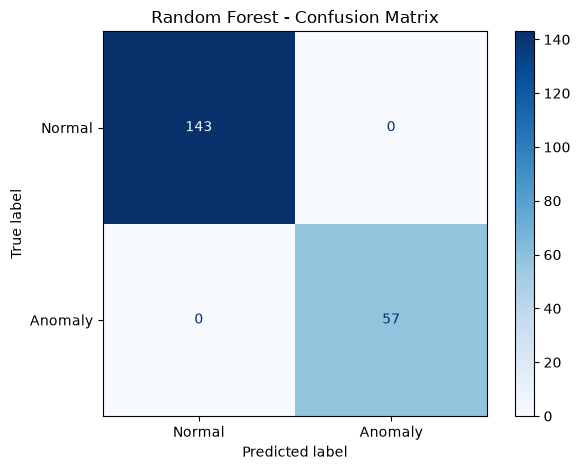

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Train the model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = rf_model.predict(X_test)

# Evaluate
print("Random Forest Results")
print("-" * 35)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Anomaly"],
        zero_division=0
    )
)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Normal", "Anomaly"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

MODEL COMPARISON ON THE TEST SET


c:\Users\mouna\Downloads\AI_BurnIn_Anomaly_Detection\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Random Forest,1.0,1.0,1.0,1.0,1.0
Logistic Regression,1.0,1.0,1.0,1.0,1.0
SVM,1.0,1.0,1.0,1.0,1.0


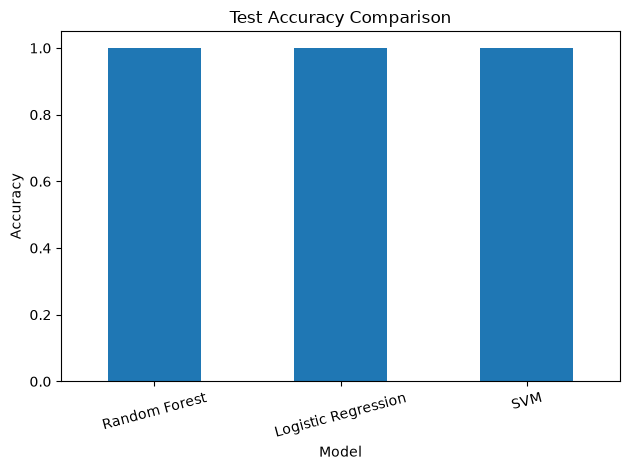

In [11]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).set_index("Model")

print("MODEL COMPARISON ON THE TEST SET")
display(results_df.round(4))

results_df["Accuracy"].plot(
    kind="bar",
    ylim=(0, 1.05),
    title="Test Accuracy Comparison"
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [12]:
print("Number of unique lots:", df["Lot_ID"].nunique())
print("\nComponents per lot:")
print(df["Lot_ID"].value_counts().sort_index())

Number of unique lots: 10

Components per lot:
Lot_ID
L01    100
L02    100
L03    100
L04    100
L05    100
L06    100
L07    100
L08    100
L09    100
L10    100
Name: count, dtype: int64


Training lots: ['L01', 'L02', 'L03', 'L04', 'L05', 'L06', 'L07', 'L08']
Testing lots: ['L09', 'L10']
Training samples: 800
Testing samples: 200

Training label counts:
Ground_Truth
0    580
1    220
Name: count, dtype: int64

Testing label counts:
Ground_Truth
0    137
1     63
Name: count, dtype: int64

UNSEEN-LOT EVALUATION
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       137
     Anomaly       1.00      1.00      1.00        63

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



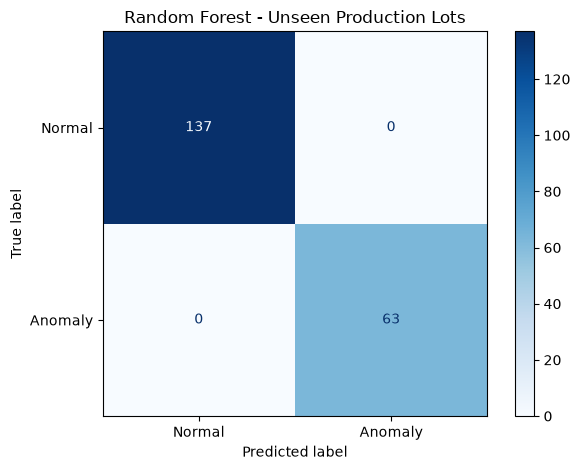

In [13]:

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Separate entire production lots
train_df = df[df["Lot_ID"].isin(
    ["L01", "L02", "L03", "L04", "L05", "L06", "L07", "L08"]
)].copy()

test_df = df[df["Lot_ID"].isin(["L09", "L10"])].copy()

feature_columns = [
    "Value_0h",
    "Value_24h",
    "Value_96h",
    "Value_168h"
]

X_train_lot = train_df[feature_columns]
y_train_lot = train_df["Ground_Truth"].map({
    "Normal": 0,
    "Anomaly": 1
})

X_test_lot = test_df[feature_columns]
y_test_lot = test_df["Ground_Truth"].map({
    "Normal": 0,
    "Anomaly": 1
})

print("Training lots:", sorted(train_df["Lot_ID"].unique()))
print("Testing lots:", sorted(test_df["Lot_ID"].unique()))
print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nTraining label counts:")
print(y_train_lot.value_counts())

print("\nTesting label counts:")
print(y_test_lot.value_counts())

# Train using only the training lots
lot_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

lot_model.fit(X_train_lot, y_train_lot)

# Evaluate on completely held-out lots
lot_predictions = lot_model.predict(X_test_lot)

print("\nUNSEEN-LOT EVALUATION")
print("Accuracy:", round(
    accuracy_score(y_test_lot, lot_predictions), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test_lot,
    lot_predictions,
    labels=[0, 1],
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_lot,
    lot_predictions,
    labels=[0, 1],
    display_labels=["Normal", "Anomaly"],
    cmap="Blues"
)

plt.title("Random Forest - Unseen Production Lots")
plt.tight_layout()
plt.show()


SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
2,Value_96h,0.25899
3,Value_168h,0.21867
1,Value_24h,0.02559
0,Value_0h,0.00030


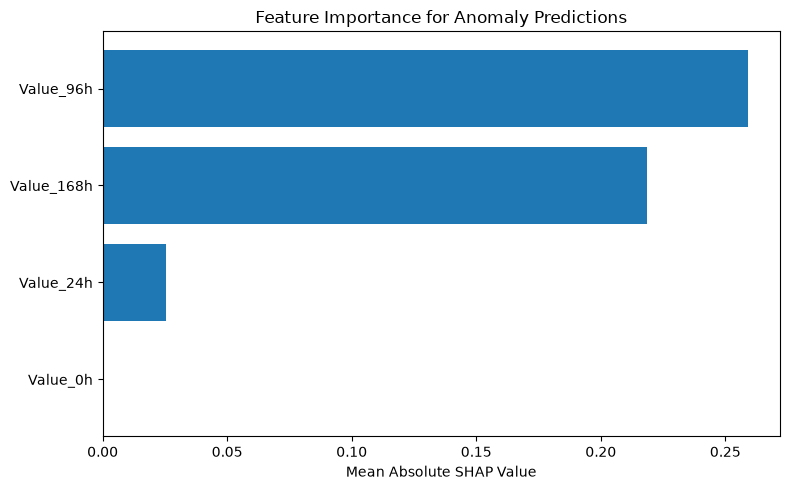

In [14]:

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Explain the Random Forest trained on L01-L08
explainer = shap.TreeExplainer(lot_model)
shap_values = explainer.shap_values(X_test_lot)

# Extract SHAP values for the Anomaly class
if isinstance(shap_values, list):
    anomaly_shap = shap_values[1]
elif getattr(shap_values, "ndim", 0) == 3:
    anomaly_shap = shap_values[:, :, 1]
else:
    anomaly_shap = shap_values

# Rank features by mean absolute SHAP value
importance = pd.DataFrame({
    "Feature": feature_columns,
    "Mean_Absolute_SHAP": abs(anomaly_shap).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

print("SHAP FEATURE IMPORTANCE")
display(importance.round(5))

# Visualize the results
plt.figure(figsize=(8, 5))
plt.barh(
    importance["Feature"][::-1],
    importance["Mean_Absolute_SHAP"][::-1]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.title("Feature Importance for Anomaly Predictions")
plt.tight_layout()
plt.show()


In [15]:

from pathlib import Path
import joblib

# Create output folders
models_dir = Path("../models")
results_dir = Path("../results")
models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model
joblib.dump(lot_model, models_dir / "burnin_random_forest.pkl")

# Save SHAP importance table
importance.to_csv(
    results_dir / "shap_feature_importance.csv",
    index=False
)

# Save unseen-lot predictions for later analysis
prediction_results = test_df[
    ["Component_ID", "Lot_ID", "Ground_Truth"]
].copy()

prediction_results["Predicted_Label"] = [
    "Anomaly" if value == 1 else "Normal"
    for value in lot_predictions
]

prediction_results.to_csv(
    results_dir / "unseen_lot_predictions.csv",
    index=False
)

print("Model and results saved successfully!")
print("Model:", models_dir / "burnin_random_forest.pkl")
print("SHAP results:", results_dir / "shap_feature_importance.csv")
print("Predictions:", results_dir / "unseen_lot_predictions.csv")


Model and results saved successfully!
Model: ..\models\burnin_random_forest.pkl
SHAP results: ..\results\shap_feature_importance.csv
Predictions: ..\results\unseen_lot_predictions.csv
